# 04 – Evaluation: Fine-Tuning vs RAG

**Operation Ledger-Mind: The Financial Intelligence**

**Fair comparison:** both systems run on the same base model (`finetune_model` in config) with the same system prompt and greedy decoding.
- Fine-tuned: base model + LoRA adapters, no retrieval
- RAG: same base model with adapters disabled, answering from retrieved context

**Judge:** `llm_model` in config at temperature 0, given only the question, the reference and the answer (never the retrieved context).

In [1]:
# Setup
import sys
import os
from pathlib import Path
from dotenv import load_dotenv
import json
import random
import re
import time
import pandas as pd
import matplotlib.pyplot as plt
from rouge_score import rouge_scorer
import warnings
import logging

warnings.filterwarnings('ignore')
logging.getLogger('weaviate').setLevel(logging.ERROR)
logging.getLogger('sentence_transformers').setLevel(logging.ERROR)

sys.path.append(str(Path.cwd().parent))
load_dotenv()

from src.services.llm_services import load_config, get_llm
config = load_config("../src/config/config.yaml")
judge_llm = get_llm({**config, "temperature": 0})
print(f"Judge LLM ready: {config['llm_model']}")

Judge LLM ready: openai/gpt-oss-120b


In [2]:
# Load test data (random sample so it is not just the first pages of the report)
test_file = Path(config['artifacts_root']) / "data_factory" / "golden_test_set.jsonl"

with open(test_file) as f:
    test_data = [json.loads(line) for line in f]

NUM_SAMPLES = 50
eval_samples = random.Random(42).sample(test_data, min(NUM_SAMPLES, len(test_data)))
print(f"Loaded {len(eval_samples)} of {len(test_data)} test samples")

Loaded 50 of 349 test samples


In [3]:
# Both systems share one base model (see inference_utils.py)
from inference_utils import query_finetuned, query_rag

<frozen importlib._bootstrap>:488: DeprecationWarning: builtin type SwigPyPacked has no __module__ attribute
<frozen importlib._bootstrap>:488: DeprecationWarning: builtin type SwigPyObject has no __module__ attribute


Loading unsloth/Llama-3.2-3B-Instruct on mps...


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

/Users/sasiriakalanka/Large Documents/Programmes/AI/Zuu/AI/operation_ledger_mind/.venv/lib/python3.12/site-packages/peft/config.py:220: UserWarning: Unexpected keyword arguments ['kasa_config', 'monteclora_config', 'velora_config'] for class LoraConfig, these are ignored. This probably means that you're loading a configuration file that was saved using a higher version of the library and additional parameters have been introduced since. It is highly recommended to upgrade the PEFT version before continuing (e.g. by running `pip install -U peft`).
  warnings.warn(
/Users/sasiriakalanka/Large Documents/Programmes/AI/Zuu/AI/operation_ledger_mind/.venv/lib/python3.12/site-packages/torch/jit/_script.py:362: DeprecationWarning: `torch.jit.script_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Adapters loaded from artifacts/adapters/final_adapters_baseline


/Users/sasiriakalanka/Large Documents/Programmes/AI/Zuu/AI/operation_ledger_mind/src/services/llm_services.py:129: LangChainDeprecationWarning: The class `HuggingFaceEmbeddings` was deprecated in LangChain 0.2.2 and will be removed in 1.0. An updated version of the class exists in the `langchain-huggingface package and should be used instead. To use it run `pip install -U `langchain-huggingface` and import as `from `langchain_huggingface import HuggingFaceEmbeddings``.
  return HuggingFaceEmbeddings(


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
{"action":"startup","build_git_commit":"4258bdfc2","build_go_version":"go1.23.3","build_image_tag":"HEAD","build_wv_version":"1.27.3","default_vectorizer_module":"none","level":"info","msg":"the default vectorizer modules is set to \"none\", as a result all new schema classes without an explicit vectorizer setting, will use this vectorizer","time":"2026-11-20T06:38:33+05:30"}
{"action":"startup","auto_schema_enabled":true,"build_git_commit":"4258bdfc2","build_go_version":"go1.23.3","build_image_tag":"HEAD","build_wv_version":"1.27.3","level":"info","msg":"auto schema enabled setting is set to \"true\"","time":"2026-11-20T06:38:33+05:30"}
{"build_git_commit":"4258bdfc2","buil

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: cross-encoder/ms-marco-MiniLM-L-6-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


query_finetuned() and query_rag() ready


In [4]:
# Evaluation functions
scorer = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=True)

def calculate_rouge_l(prediction, reference):
    return scorer.score(reference, prediction)['rougeL'].fmeasure

def llm_as_judge(question, generated, reference, judge_llm, max_attempts=3):
    """Same prompt for both systems. Returns None if the judge never gives a score."""
    prompt = f"""You are evaluating a financial QA system on Uber's 2024 Annual Report.

Score the generated answer from 1 to 5 against the reference answer:
5 - Completely accurate, matches reference
4 - Mostly accurate, minor omissions
3 - Partially correct, key facts missing
2 - Mostly wrong or vague
1 - Completely wrong or hallucinated

Question: {question}
Reference answer: {reference}
Generated answer: {generated}

Reply with ONLY a single digit (1-5):"""

    for attempt in range(max_attempts):
        try:
            text = judge_llm.invoke(prompt).content.strip()
        except Exception as e:
            if "429" in str(e):
                time.sleep(5 * 2 ** attempt)
                continue
            raise
        match = re.search(r'\b([1-5])\b', text)
        if match:
            return int(match.group(1))
    return None

print("Evaluation functions ready")

Evaluation functions ready


In [5]:
# Run evaluation: each sample is saved as it finishes, so re-running this cell resumes.
# Delete the results file to start over (e.g. after changing a model or prompt).
from tqdm import tqdm

results_file = Path(config['artifacts_root']) / "evaluation" / "results.jsonl"
results_file.parent.mkdir(parents=True, exist_ok=True)
results_file.touch(exist_ok=True)

with open(results_file) as f:
    done = {json.loads(line)['question'] for line in f}

todo = [s for s in eval_samples if s['question'] not in done]
print(f"{len(eval_samples) - len(todo)} already evaluated, {len(todo)} to go")

progress = tqdm(todo, desc="Evaluating")
for sample in progress:
    question = sample['question']
    reference = sample['answer']

    start = time.time()
    ft_answer = query_finetuned(question)
    ft_latency = (time.time() - start) * 1000

    start = time.time()
    rag_result = query_rag(question, return_sources=True)
    rag_latency = (time.time() - start) * 1000

    start = time.time()
    ft_score = llm_as_judge(question, ft_answer, reference, judge_llm)
    rag_score = llm_as_judge(question, rag_result['answer'], reference, judge_llm)
    judge_time = time.time() - start

    # shows where the time goes if a step is slow
    progress.set_postfix(ft=f"{ft_latency / 1000:.0f}s", rag=f"{rag_latency / 1000:.0f}s", judge=f"{judge_time:.0f}s")

    row = {
        'question':  question,
        'reference': reference,
        'finetuned': {
            'generated':   ft_answer,
            'rouge_l':     calculate_rouge_l(ft_answer, reference),
            'judge_score': ft_score,
            'latency_ms':  ft_latency,
        },
        'rag': {
            'generated':   rag_result['answer'],
            'rouge_l':     calculate_rouge_l(rag_result['answer'], reference),
            'judge_score': rag_score,
            'latency_ms':  rag_latency,
            # did retrieval find the chunk the question was written from?
            'source_hit':  sample['chunk_id'] in [s['chunk_id'] for s in rag_result['sources']],
        },
    }
    with open(results_file, 'a') as f:
        f.write(json.dumps(row) + '\n')

# Collect results for the current sample set only
questions = {s['question'] for s in eval_samples}
with open(results_file) as f:
    rows = [r for r in map(json.loads, f) if r['question'] in questions]

ft_results = [{'question': r['question'], 'reference': r['reference'], **r['finetuned']} for r in rows]
rag_results = [{'question': r['question'], 'reference': r['reference'], **r['rag']} for r in rows]
print(f"Evaluation complete: {len(rows)} samples")

0 already evaluated, 50 to go


Evaluating: 100%|██████████| 50/50 [43:53<00:00, 52.67s/it, ft=4s, judge=1s, rag=72s]     

Evaluation complete: 50 samples


In [6]:
# Aggregate results
df_ft = pd.DataFrame(ft_results)
df_rag = pd.DataFrame(rag_results)

def summarize(name, df):
    return {
        'Model':            name,
        'Avg ROUGE-L':      round(df['rouge_l'].mean(), 3),
        'Avg Judge Score':  round(df['judge_score'].mean(), 2),
        'Unjudged':         int(df['judge_score'].isna().sum()),
        'Avg Latency (ms)': round(df['latency_ms'].mean(), 0)
    }

comparison = pd.DataFrame([
    summarize('Fine-tuned', df_ft),
    summarize('RAG', df_rag),
])

print("\n" + "="*80)
print("EVALUATION RESULTS")
print("="*80)
print(comparison.to_string(index=False))
print("="*80)
print(f"RAG retrieval hit rate (source chunk in top 5): {df_rag['source_hit'].mean():.1%}")


EVALUATION RESULTS
     Model  Avg ROUGE-L  Avg Judge Score  Unjudged  Avg Latency (ms)
Fine-tuned        0.514             2.14         0           10706.0
       RAG        0.585             4.20         0           40336.0
RAG retrieval hit rate (source chunk in top 5): 88.0%


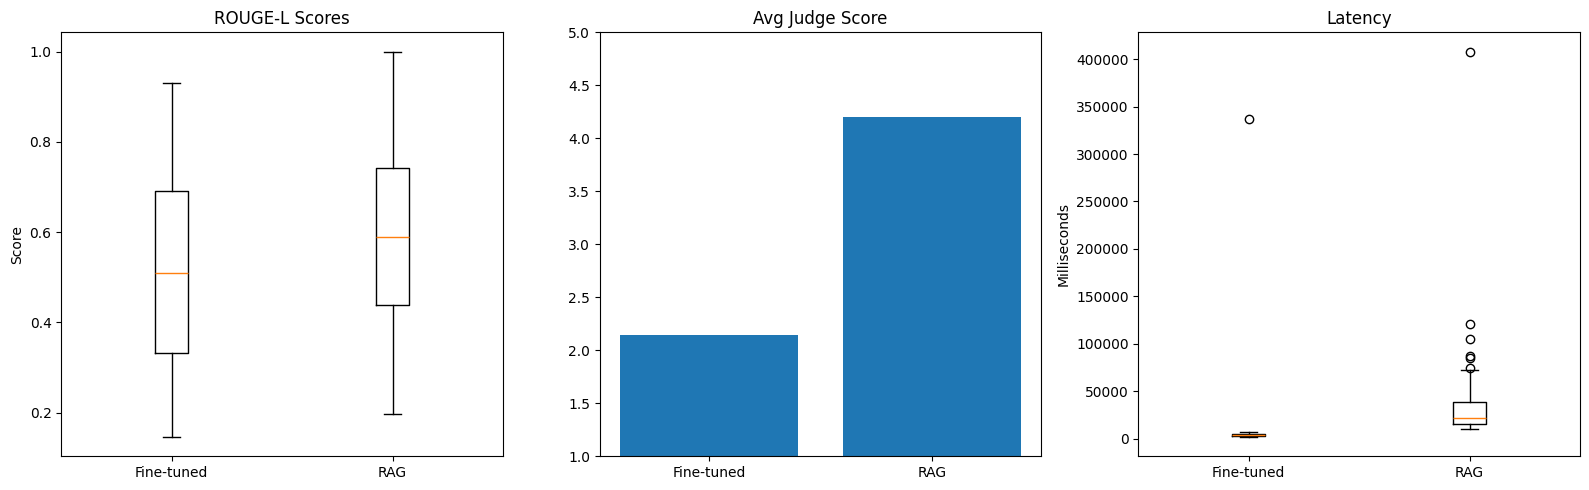


Saved figures/evaluation_results.png


In [7]:
# Visualization
Path("figures").mkdir(exist_ok=True)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].boxplot([df_ft['rouge_l'], df_rag['rouge_l']], tick_labels=['Fine-tuned', 'RAG'])
axes[0].set_title('ROUGE-L Scores')
axes[0].set_ylabel('Score')

axes[1].bar(['Fine-tuned', 'RAG'], [df_ft['judge_score'].mean(), df_rag['judge_score'].mean()])
axes[1].set_title('Avg Judge Score')
axes[1].set_ylim(1, 5)

axes[2].boxplot([df_ft['latency_ms'], df_rag['latency_ms']], tick_labels=['Fine-tuned', 'RAG'])
axes[2].set_title('Latency')
axes[2].set_ylabel('Milliseconds')

plt.tight_layout()
plt.savefig('figures/evaluation_results.png', dpi=300)
plt.show()

print("\nSaved figures/evaluation_results.png")